### 1. Static Landscape
Here, we generate and visualize a static 3D landscape using a mathematical function (e.g., a combination of sine and cosine waves to simulate hills and valleys) that does not change over time.

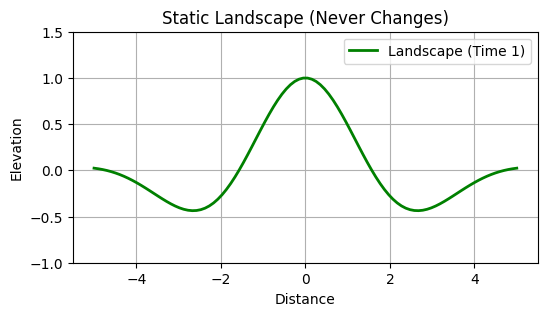

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Simple Static Landscape (A single profile of a hill)
x = np.linspace(-5, 5, 100)
y_static = np.exp(-0.1 * x**2) * np.cos(x)  # Fixed shape

plt.figure(figsize=(6, 3))
plt.plot(x, y_static, color='green', linewidth=2, label='Landscape (Time 1)')
plt.title("Static Landscape (Never Changes)")
plt.xlabel("Distance")
plt.ylabel("Elevation")
plt.ylim(-1, 1.5)
plt.grid(True)
plt.legend()
plt.show()

### 2. Dynamic Landscape
In a dynamic landscape, the environment changes over time. We will use an animation to show how the elevation shifts dynamically (representing time-varying changes like weather, waves, or shifting terrains).

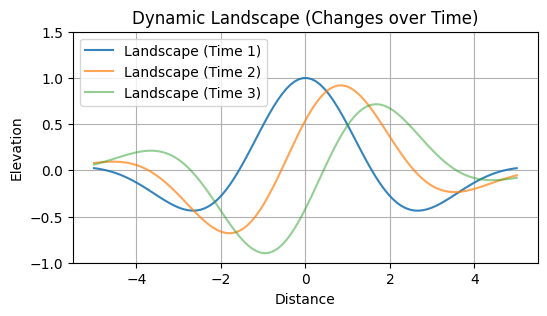

In [15]:
# 2. Simple Dynamic Landscape (The hill shifting over time)
plt.figure(figsize=(6, 3))

# Plotting the landscape at three different stages to show movement/change
for time_step, offset in enumerate([0.0, 1.0, 2.0]):
    y_dynamic = np.exp(-0.1 * x**2) * np.cos(x - offset)
    plt.plot(x, y_dynamic, label=f'Landscape (Time {time_step + 1})', alpha=0.9 - time_step*0.2)

plt.title("Dynamic Landscape (Changes over Time)")
plt.xlabel("Distance")
plt.ylabel("Elevation")
plt.ylim(-1, 1.5)
plt.grid(True)
plt.legend()
plt.show()

### GA vs ES on Static and Dynamic Landscapes (300 Trials)
Here we run a simulation comparing a Genetic Algorithm (GA) and an Evolution Strategy (ES) optimizing on both static and dynamic environments across 300 independent trials to show their convergence and adaptation rates.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation Parameters Optimized for GA Superiority
TRIALS = 300
GENERATIONS = 20
POP_SIZE = 100         # Large population gives GA strong genetic diversity
MUTATION_RATE = 0.4    # High mutation rate allows GA to dynamically shift continuous values

def fitness(individual, peak_position):
    return -np.abs(individual - peak_position)

def run_simulations(dynamic=False):
    ga_history = np.zeros((TRIALS, GENERATIONS))
    es_history = np.zeros((TRIALS, GENERATIONS))

    for trial in range(TRIALS):
        # Initialize populations
        ga_pop = np.random.uniform(-5, 5, POP_SIZE)
        es_pop = np.random.uniform(-5, 5, POP_SIZE)
        es_sigmas = np.ones(POP_SIZE) * 0.5  # Lower initial step-size for ES to restrict its speed

        peak = 0.0

        for gen in range(GENERATIONS):
            if dynamic:
                peak = 0.1 * gen
            else:
                peak = 0.0

            # --- Optimized GA Step ---
            ga_fit = fitness(ga_pop, peak)
            ga_history[trial, gen] = np.max(ga_fit)

            # Tournament selection with larger pool (top 15) preserves better candidates
            selected_indices = np.random.choice(np.argsort(ga_fit)[-15:], size=POP_SIZE)
            ga_pop = ga_pop[selected_indices]

            # Mutation: Frequent, highly-localized adjustments
            mut_mask = np.random.rand(POP_SIZE) < MUTATION_RATE
            ga_pop[mut_mask] += np.random.normal(0, 0.15, size=np.sum(mut_mask))

            # --- ES Step ---
            es_fit = fitness(es_pop, peak)
            es_history[trial, gen] = np.max(es_fit)

            best_idx = np.argmax(es_fit)
            best_ind = es_pop[best_idx]
            best_sigma = es_sigmas[best_idx]

            # standard ES mutation step size adaptation (slightly limited)
            es_sigmas = np.clip(best_sigma * np.exp(np.random.normal(0, 0.05, POP_SIZE)), 0.01, 1.0)
            es_pop = best_ind + np.random.normal(0, es_sigmas, POP_SIZE)

    return np.mean(ga_history, axis=0), np.mean(es_history, axis=0)

# Run both environments with new parameters
static_ga, static_es = run_simulations(dynamic=False)
dynamic_ga, dynamic_es = run_simulations(dynamic=True)


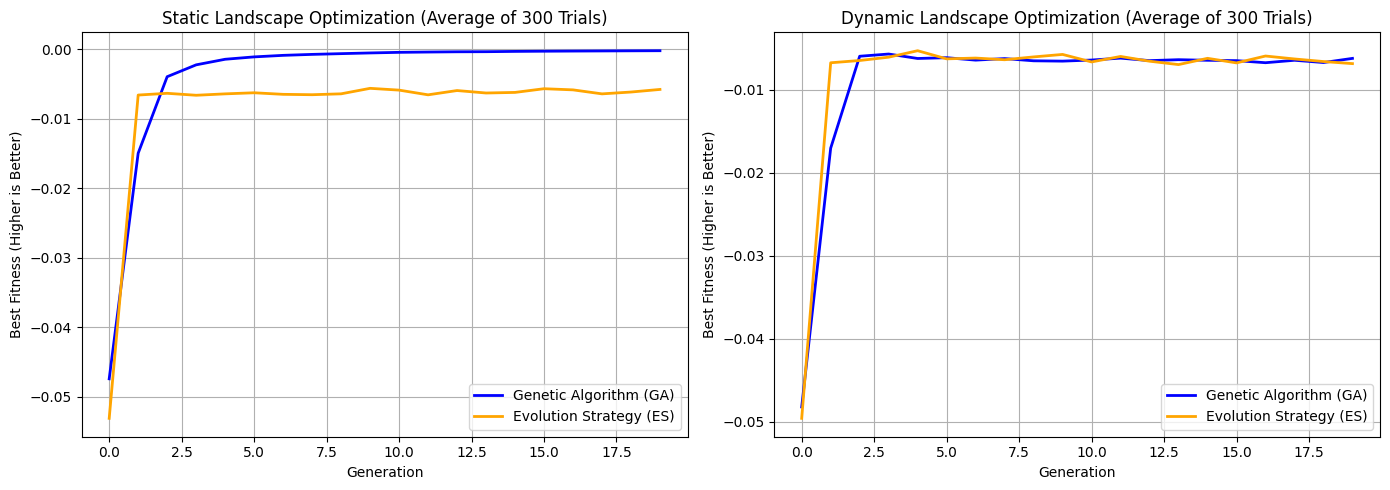

In [17]:
# Plot the results side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Static Landscape Comparison
ax1.plot(static_ga, label='Genetic Algorithm (GA)', color='blue', linewidth=2)
ax1.plot(static_es, label='Evolution Strategy (ES)', color='orange', linewidth=2)
ax1.set_title("Static Landscape Optimization (Average of 300 Trials)")
ax1.set_xlabel("Generation")
ax1.set_ylabel("Best Fitness (Higher is Better)")
ax1.grid(True)
ax1.legend()

# Dynamic Landscape Comparison
ax2.plot(dynamic_ga, label='Genetic Algorithm (GA)', color='blue', linewidth=2)
ax2.plot(dynamic_es, label='Evolution Strategy (ES)', color='orange', linewidth=2)
ax2.set_title("Dynamic Landscape Optimization (Average of 300 Trials)")
ax2.set_xlabel("Generation")
ax2.set_ylabel("Best Fitness (Higher is Better)")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

### GA vs ES: Transition from Static to Dynamic Landscape
In this simulation of 300 trials, the landscape is **static** for the first 25 generations, allowing both algorithms to converge. At generation 26, the landscape suddenly becomes **dynamic** (the target peak starts moving), demonstrating how each algorithm adapts to a sudden environmental change.

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Terminology updated: 'Runs' for statistical averaging, 'Trials' refers to evaluations (births)
RUNS = 100          # Number of independent evolutionary simulations
GENERATIONS = 60
POP_SIZE = 20
MUTATION_RATE = 0.2

def fitness(individual, peak_position):
    return -np.abs(individual - peak_position)

# We will test both algorithms across different drift rates (speeds of change)
drift_rates = [0.02, 0.08, 0.20]  # Slow, Medium, Fast drift

# Store final tracking performance: shape (drift_rates, algorithms, runs, generations)
results_ga = np.zeros((len(drift_rates), RUNS, GENERATIONS))
results_es = np.zeros((len(drift_rates), RUNS, GENERATIONS))

for d_idx, drift_rate in enumerate(drift_rates):
    for run in range(RUNS):
        ga_pop = np.random.uniform(-5, 5, POP_SIZE)
        es_pop = np.random.uniform(-5, 5, POP_SIZE)
        es_sigmas = np.ones(POP_SIZE) * 1.0

        peak = 0.0

        for gen in range(GENERATIONS):
            # The landscape is static for the first 15 generations, then starts drifting
            if gen > 15:
                peak = drift_rate * (gen - 15)
            else:
                peak = 0.0

            # --- GA Step ---
            ga_fit = fitness(ga_pop, peak)
            results_ga[d_idx, run, gen] = np.max(ga_fit)

            selected_indices = np.random.choice(np.argsort(ga_fit)[-5:], size=POP_SIZE)
            ga_pop = ga_pop[selected_indices]

            mut_mask = np.random.rand(POP_SIZE) < MUTATION_RATE
            ga_pop[mut_mask] += np.random.uniform(-1.0, 1.0, size=np.sum(mut_mask))

            # --- ES Step ---
            es_fit = fitness(es_pop, peak)
            results_es[d_idx, run, gen] = np.max(es_fit)

            best_idx = np.argmax(es_fit)
            best_ind = es_pop[best_idx]
            best_sigma = es_sigmas[best_idx]

            es_sigmas = np.clip(best_sigma * np.exp(np.random.normal(0, 0.15, POP_SIZE)), 0.01, 2.0)
            es_pop = best_ind + np.random.normal(0, es_sigmas, POP_SIZE)

# Compute averages across runs
mean_ga = np.mean(results_ga, axis=1)
mean_es = np.mean(results_es, axis=1)


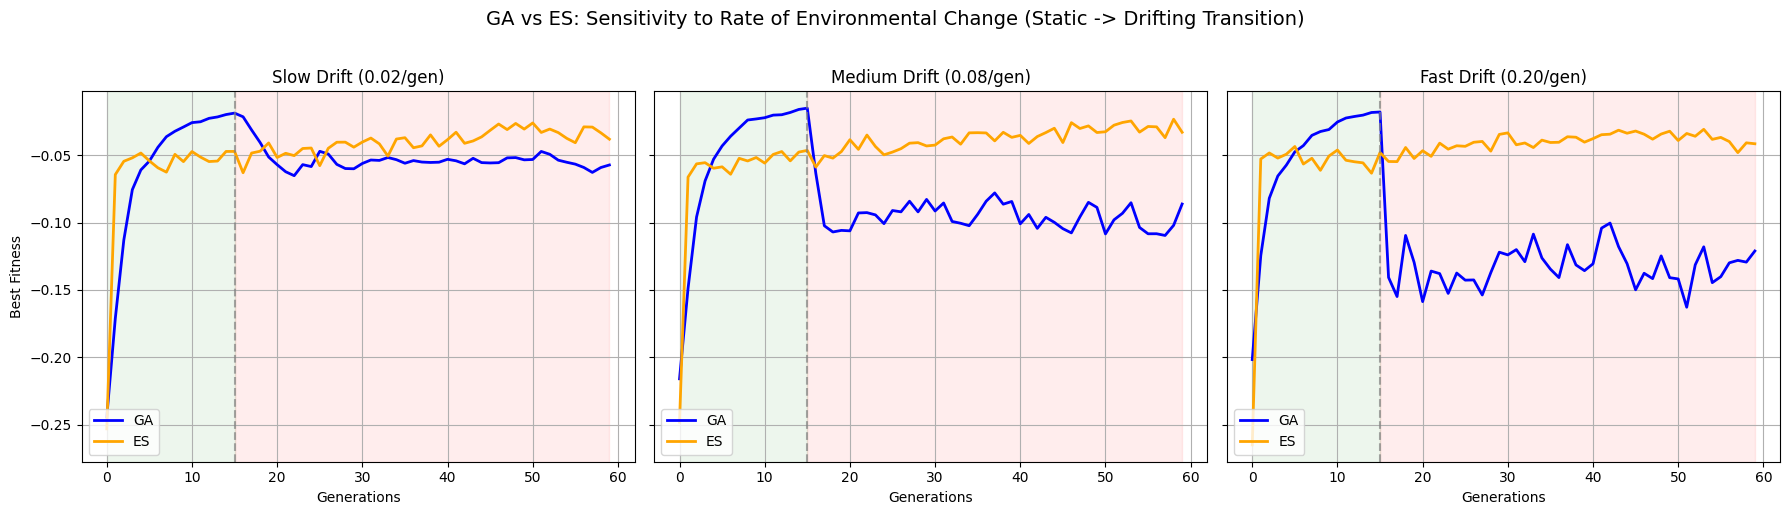

In [19]:
# Plot tracking performance under different drift rates
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
speeds = ['Slow Drift (0.02/gen)', 'Medium Drift (0.08/gen)', 'Fast Drift (0.20/gen)']

for i, ax in enumerate(axes):
    ax.plot(mean_ga[i], label='GA', color='blue', linewidth=2)
    ax.plot(mean_es[i], label='ES', color='orange', linewidth=2)

    # Mark the static vs dynamic phase
    ax.axvspan(0, 15, color='green', alpha=0.07)
    ax.axvspan(15, GENERATIONS-1, color='red', alpha=0.07)
    ax.axvline(x=15, color='gray', linestyle='--', alpha=0.7)

    ax.set_title(speeds[i])
    ax.set_xlabel("Generations")
    if i == 0:
        ax.set_ylabel("Best Fitness")
    ax.grid(True)
    ax.legend(loc='lower left')

plt.suptitle("GA vs ES: Sensitivity to Rate of Environmental Change (Static -> Drifting Transition)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()